<a href="https://colab.research.google.com/github/HC-AIGroup/CS5330_F26/blob/main/Module3/CS5330_Module3_Part2_Hands_On.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

OpenCV 5.0.0


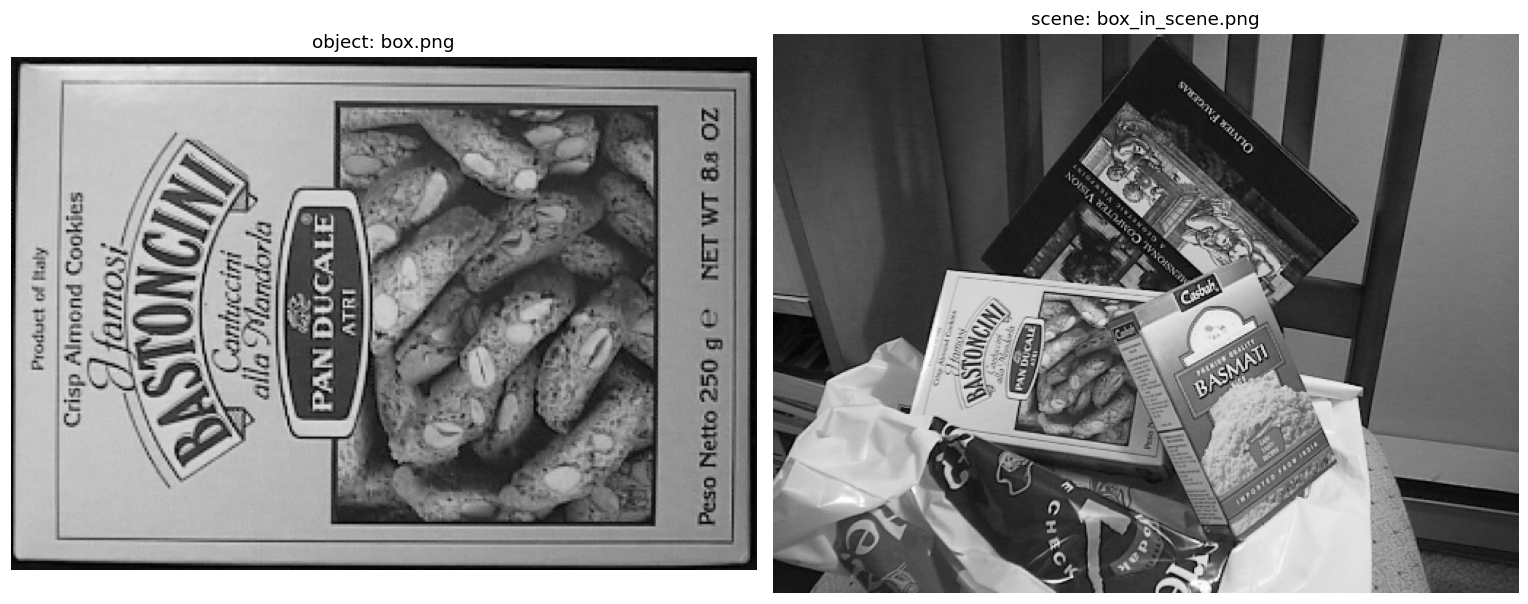

In [1]:
# PART 0 · SETUP — run this first (about 10 seconds)
import cv2, numpy as np, matplotlib.pyplot as plt, urllib.request
plt.rcParams["figure.dpi"] = 110
print("OpenCV", cv2.__version__)

BASE = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
def load(name):
    data = urllib.request.urlopen(BASE + name).read()
    return cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)

def show(*imgs, titles=(), size=(14, 6)):
    plt.figure(figsize=size)
    for i, img in enumerate(imgs):
        plt.subplot(1, len(imgs), i + 1)
        plt.imshow(img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap="gray")
        plt.title(titles[i] if i < len(titles) else ""); plt.axis("off")
    plt.tight_layout(); plt.show()

box, scene = load("box.png"), load("box_in_scene.png")
box_g, scene_g = cv2.cvtColor(box, cv2.COLOR_BGR2GRAY), cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)
show(box, scene, titles=("object: box.png", "scene: box_in_scene.png"))

k = 0.04, threshold = 0.01 x R.max()  ->  3715 corner pixels


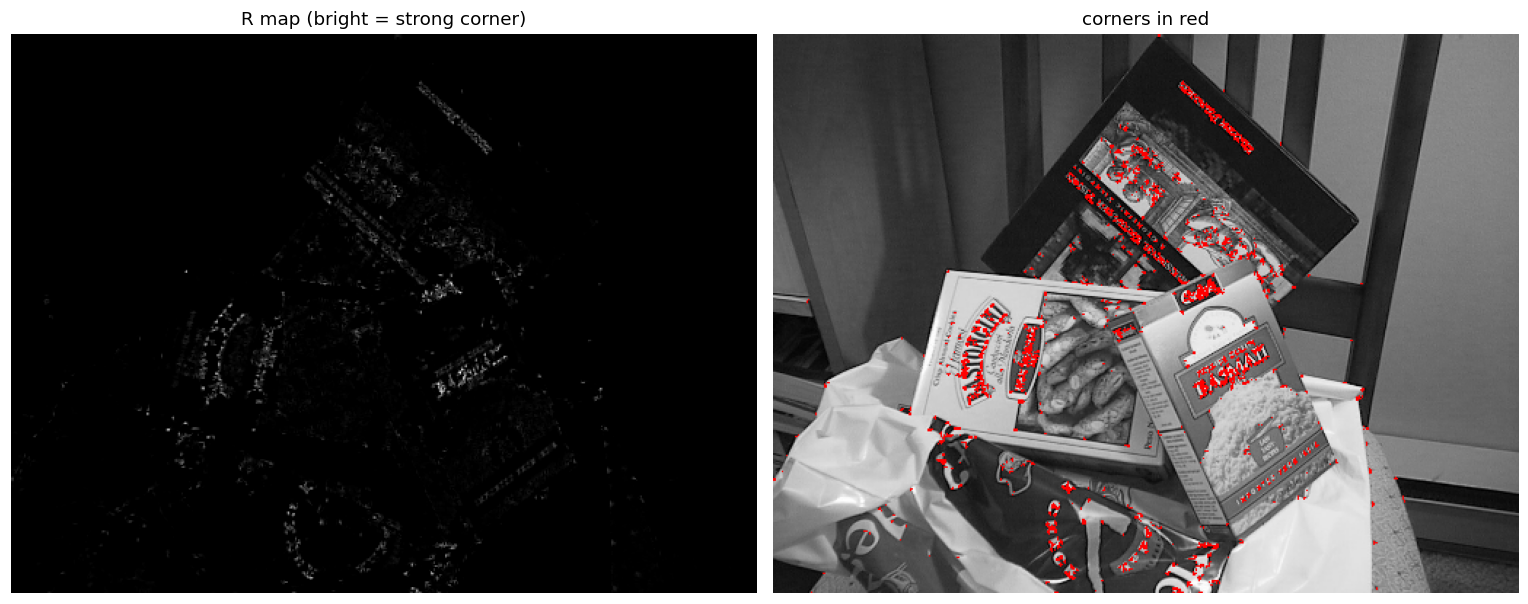

k = 0.04  threshold = 0.01 x R.max()  ->   3715 pixels
k = 0.04  threshold = 0.05 x R.max()  ->   1112 pixels
k = 0.06  threshold = 0.01 x R.max()  ->   3144 pixels
k = 0.06  threshold = 0.05 x R.max()  ->    967 pixels


In [2]:
# PART 1 · HARRIS CORNERS
# PREDICT FIRST: where will most corners be — on the walls, on the boxes, or on the text?
# TRY IT: change THRESH to 0.05 and run again.

K, THRESH = 0.04, 0.01            # change these and run again

R = cv2.cornerHarris(np.float32(scene_g), blockSize=2, ksize=3, k=K)
corners = R > THRESH * R.max()
vis = scene.copy(); vis[corners] = (0, 0, 255)
print(f"k = {K}, threshold = {THRESH} x R.max()  ->  {int(corners.sum())} corner pixels")
show(np.maximum(R, 0) ** 0.5, vis, titles=("R map (bright = strong corner)", "corners in red"))

# The two knobs side by side
for k in (0.04, 0.06):
    for frac in (0.01, 0.05):
        Rk = cv2.cornerHarris(np.float32(scene_g), 2, 3, k)
        print(f"k = {k}  threshold = {frac} x R.max()  ->  {int((Rk > frac * Rk.max()).sum()):5d} pixels")

# CHECK YOURSELF:
# - Corners sit on text and box edges, not on flat walls.
# - About 3,700 pixels at k=0.04 / 0.01. Threshold 0.05 drops it to about 1,100;
#   k=0.06 only to about 3,100. The threshold matters far more than k.
# - Red marks come in clusters: non-maximum suppression would keep one per cluster.

In [3]:
#Harris by hand
# PART 2 · HARRIS BY HAND (the 3 warm-up patches)
# PREDICT FIRST: which patch is the corner? Is R for patch C positive or negative?

def harris_from_patch(Ix, Iy, k=0.04):
    Ix, Iy = np.array(Ix, float), np.array(Iy, float)
    H = np.array([[np.sum(Ix * Ix), np.sum(Ix * Iy)], [np.sum(Ix * Iy), np.sum(Iy * Iy)]])
    det, tr = np.linalg.det(H), np.trace(H)
    R = det - k * tr ** 2
    return H, det, tr, R, ("corner" if R > 0 and det > 0 else "edge" if R < 0 else "flat")

patches = {   # (Ix, Iy) for each pixel, same numbers as the warm-up slide
    "A": dict(Ix=[[2, 2, 0], [2, 2, 0], [0, 0, 0]], Iy=[[0, 0, 0], [0, 0, 2], [2, 2, 2]]),
    "B": dict(Ix=[[3, 3, 3], [3, 3, 3], [0, 0, 0]], Iy=[[0, 0, 0], [0, 0, 0], [0, 0, 0]]),
    "C": dict(Ix=[[2, 2, 0], [2, 2, 0], [2, 2, 0]], Iy=[[2, 2, 0], [2, 2, 0], [2, 2, 0]]),
}
for name, p in patches.items():
    H, det, tr, R, label = harris_from_patch(p["Ix"], p["Iy"])
    print(f"{name}: H = {H.astype(int).tolist()}  det = {det:.0f}  trace = {tr:.0f}  R = {R:8.2f}  ->  {label}")

# CHECK YOURSELF:
# - A is the corner: det = 256, R ≈ 215 > 0 (gradients in two directions).
# - B is an edge: only Ix, det = 0, R < 0.
# - C is also an edge: big Ix AND Iy, but always together (a diagonal edge).
#   The off-diagonal 24 makes det = 0, so R ≈ -92.

A: H = [[16, 0], [0, 16]]  det = 256  trace = 32  R =   215.04  ->  corner
B: H = [[54, 0], [0, 0]]  det = 0  trace = 54  R =  -116.64  ->  edge
C: H = [[24, 24], [24, 24]]  det = 0  trace = 48  R =   -92.16  ->  edge


604 keypoints in the box, 969 in the scene; descriptors: (604, 128)


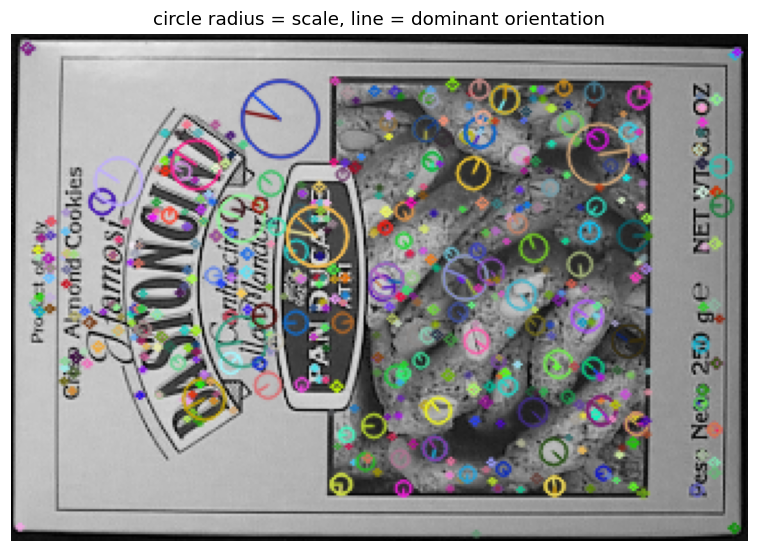

In [4]:
# PART 3 · SIFT KEYPOINTS
# PREDICT FIRST: will the small box or the big scene have more keypoints? Roughly how many?

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(box_g, None)
kp2, des2 = sift.detectAndCompute(scene_g, None)
print(f"{len(kp1)} keypoints in the box, {len(kp2)} in the scene; descriptors: {des1.shape}")
rich = cv2.drawKeypoints(box, kp1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show(rich, titles=("circle radius = scale, line = dominant orientation",), size=(7, 6))

# CHECK YOURSELF:
# - About 600 in the box, about 970 in the scene. The box is small but full of text.
# - Circle radius = scale (big on big structures, small on fine text); line = orientation.
# - Every keypoint has 128 numbers: 4 x 4 cells x 8 directions -> shape (604, 128).

raw nearest neighbors: 604   after ratio 0.75: 80
  ratio 0.6: 63 matches
  ratio 0.75: 80 matches
  ratio 0.9: 186 matches


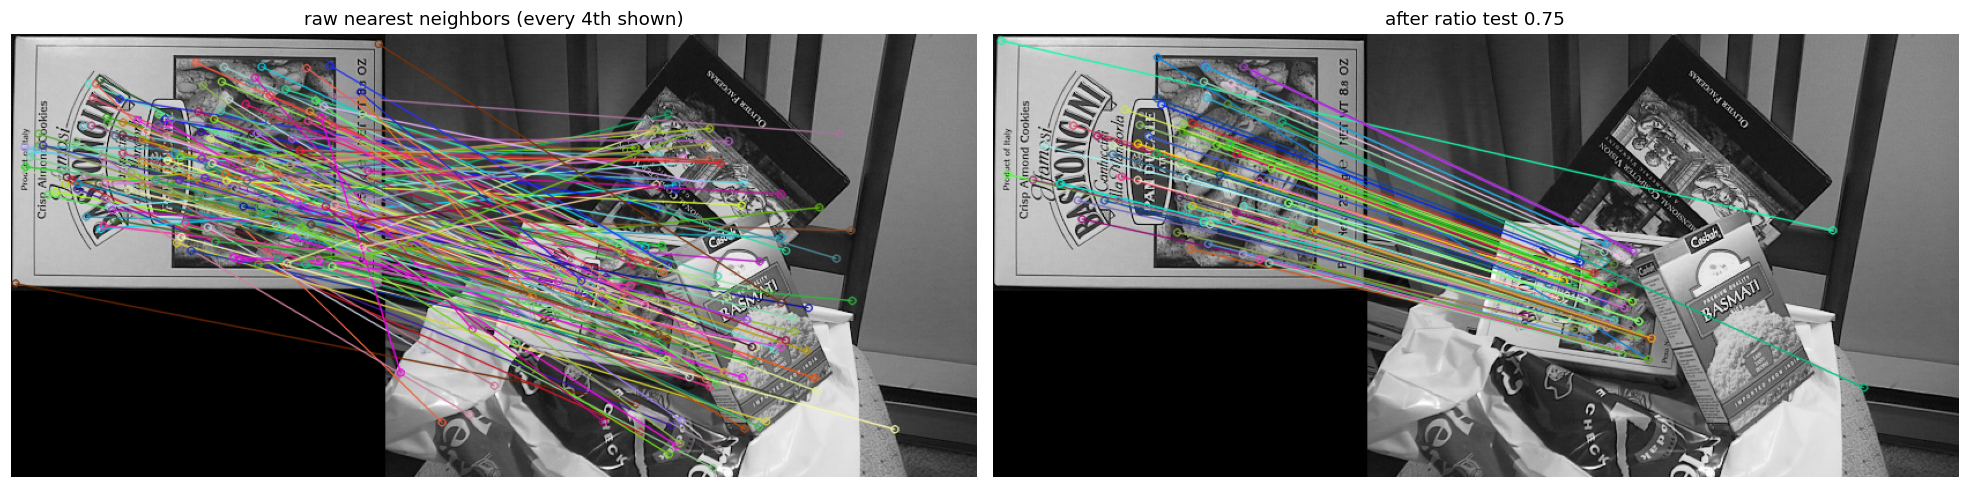

In [5]:
# PART 4 · MATCHING: RAW vs. RATIO TEST
# PREDICT FIRST: out of ~600 box keypoints, how many survive the ratio test at 0.75?
# TRY IT: set RATIO = 0.9 and run again. More wrong (crossing) lines? Set it back to 0.75 before Part 5.

flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))   # 1 = KD-tree for SIFT
knn = [p for p in flann.knnMatch(des1, des2, k=2) if len(p) == 2]
ratio_filter = lambda pairs, r: [m for m, n in pairs if m.distance < r * n.distance]

RATIO = 0.75                                     # try: 0.6 / 0.75 / 0.9
good = ratio_filter(knn, RATIO)
raw = [m for m, n in knn]
print(f"raw nearest neighbors: {len(raw)}   after ratio {RATIO}: {len(good)}")
for r in (0.6, 0.75, 0.9):
    print(f"  ratio {r}: {len(ratio_filter(knn, r))} matches")

show(cv2.drawMatches(box, kp1, scene, kp2, raw[::4], None, flags=2),
     cv2.drawMatches(box, kp1, scene, kp2, good, None, flags=2),
     titles=("raw nearest neighbors (every 4th shown)", f"after ratio test {RATIO}"), size=(18, 6))

# CHECK YOURSELF:
# - Raw: 604. Every keypoint gets a match, because a nearest neighbor always exists.
# - After the ratio test: only about 80. (0.6 -> ~63, 0.9 -> ~186)
# - Most lines look right, but a few wrong ones still survive. That's why we need RANSAC.

75 inliers of 80  ->  w = 0.94;  rounds needed for 99%: 4
H =
 [[ 4.42000e-01 -1.63000e-01  1.18845e+02]
 [ 1.00000e-03  4.05000e-01  1.60919e+02]
 [-0.00000e+00 -0.00000e+00  1.00000e+00]]


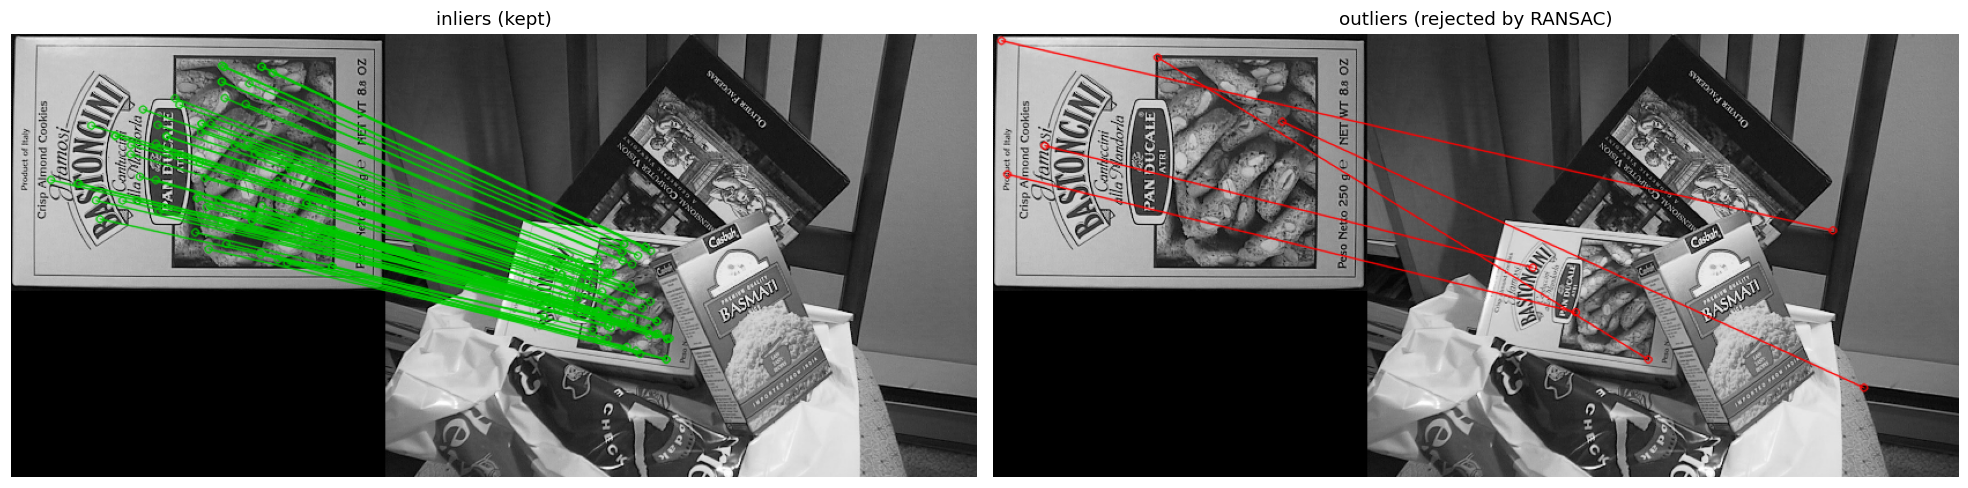

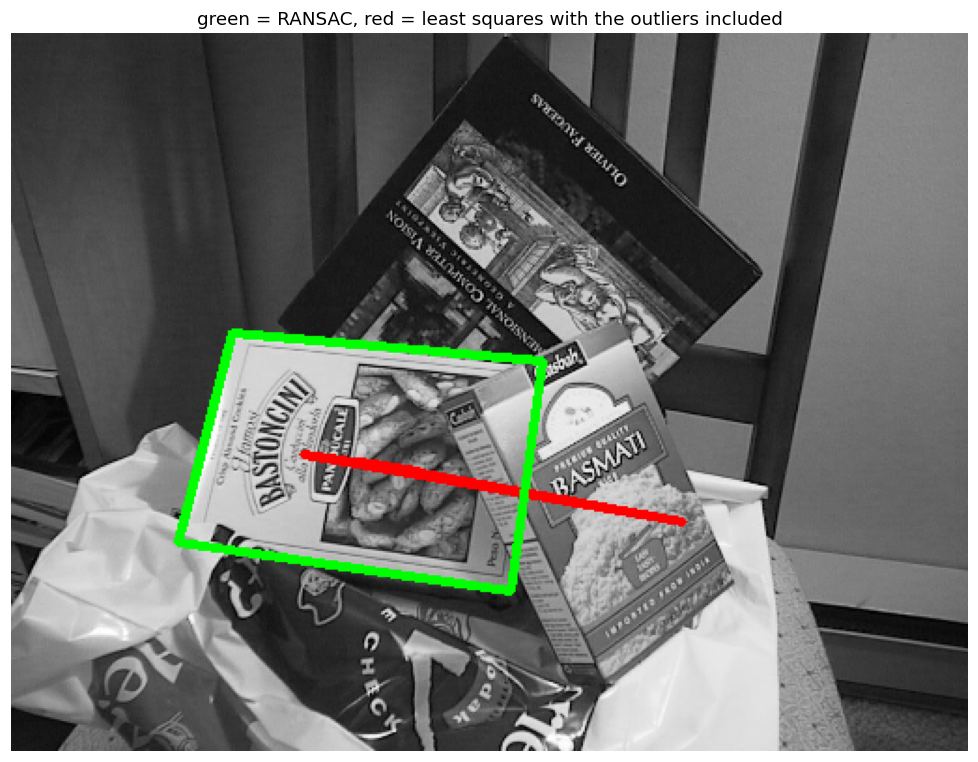

In [6]:
# PART 5 · RANSAC: FIND THE BOX
# PREDICT FIRST: (1) what fraction of the ~80 matches are inliers?
#                (2) will plain least squares on ALL matches still find the box?
# TRY IT: change the 5.0 in findHomography to 1.0, then to 50.0. How do the inliers change? Why?

src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
inl = mask.ravel().astype(bool)
w = inl.mean()
N = int(np.ceil(np.log(1 - 0.99) / np.log(1 - w ** 4)))
print(f"{inl.sum()} inliers of {len(good)}  ->  w = {w:.2f};  rounds needed for 99%: {N}")
print("H =\n", np.round(H, 3))

# outlines of the box: RANSAC (green) vs least squares on all matches (red)
h, wd = box_g.shape
corners_box = np.float32([[0, 0], [wd, 0], [wd, h], [0, h]]).reshape(-1, 1, 2)
H_ls, _ = cv2.findHomography(src, dst, 0)
out = scene.copy()
cv2.polylines(out, [np.int32(cv2.perspectiveTransform(corners_box, H_ls))], True, (0, 0, 255), 3)
cv2.polylines(out, [np.int32(cv2.perspectiveTransform(corners_box, H))], True, (0, 255, 0), 3)

inlier_view  = cv2.drawMatches(box, kp1, scene, kp2, good, None, matchColor=(0, 200, 0),
                               matchesMask=inl.astype(int).tolist(), flags=2)
outlier_view = cv2.drawMatches(box, kp1, scene, kp2, good, None, matchColor=(0, 0, 255),
                               matchesMask=(~inl).astype(int).tolist(), flags=2)
show(inlier_view, outlier_view, titles=("inliers (kept)", "outliers (rejected by RANSAC)"), size=(18, 6))
show(out, titles=("green = RANSAC, red = least squares with the outliers included",), size=(9, 7))

# CHECK YOURSELF:
# - About 75 of 80 are inliers (w ≈ 0.94), so only ~4 rounds are needed for 99%.
# - Green outline (RANSAC) sits exactly on the box.
# - Red outline (least squares on all 80) is way off: only 5 wrong matches, but each is
#   hundreds of pixels off and the error is SQUARED, so they pull H away.
# - The outline = the 4 corners of the box image sent through H, then connected.

H_true:
 [[ 9.0e-01  8.0e-02  4.0e+01]
 [-6.0e-02  9.5e-01  2.5e+01]
 [ 2.0e-04  1.0e-04  1.0e+00]] 
H_est:
 [[ 9.02400e-01  7.92000e-02  3.98901e+01]
 [-5.88000e-02  9.50100e-01  2.49308e+01]
 [ 2.00000e-04  1.00000e-04  1.00000e+00]]
corner error (px): [0.13 0.56 0.13 0.5 ]


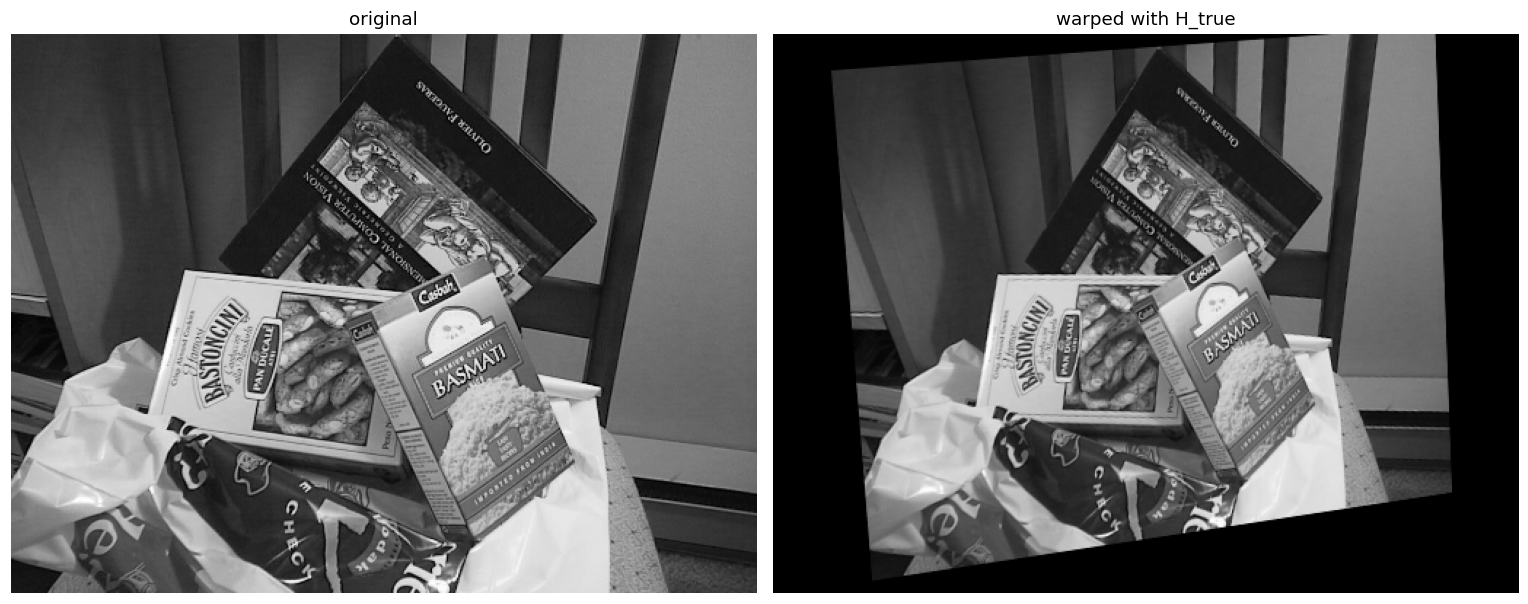

In [7]:
# PART 6 · RECOVER A HOMOGRAPHY WE CREATED
# PREDICT FIRST: how many pixels off will the estimated H be at the corners: 0.1, 1, or 10?

H_true = np.array([[0.90,  0.08, 40.0],
                   [-0.06, 0.95, 25.0],
                   [2e-4,  1e-4,  1.0]])
hs, ws = scene_g.shape
view2 = cv2.warpPerspective(scene_g, H_true, (ws, hs))

ka, da = sift.detectAndCompute(scene_g, None)
kb, db = sift.detectAndCompute(view2, None)
g = ratio_filter([p for p in flann.knnMatch(da, db, k=2) if len(p) == 2], 0.75)
A = np.float32([ka[m.queryIdx].pt for m in g]).reshape(-1, 1, 2)
B = np.float32([kb[m.trainIdx].pt for m in g]).reshape(-1, 1, 2)
H_est, _ = cv2.findHomography(A, B, cv2.RANSAC, 5.0)
H_est /= H_est[2, 2]                         # H is only defined up to scale

pts = np.float32([[0, 0], [ws, 0], [ws, hs], [0, hs]]).reshape(-1, 1, 2)
err = np.linalg.norm(cv2.perspectiveTransform(pts, H_true) - cv2.perspectiveTransform(pts, H_est), axis=2)
print("H_true:\n", H_true, "\nH_est:\n", np.round(H_est, 4))
print("corner error (px):", np.round(err.ravel(), 2))
show(scene_g, view2, titles=("original", "warped with H_true"))

# CHECK YOURSELF:
# - Corner error is about 0.1–0.6 px: less than one pixel.
# - We divide by H_est[2,2] because H and 2·H give the same mapping (that's why 8 DOF, not 9).

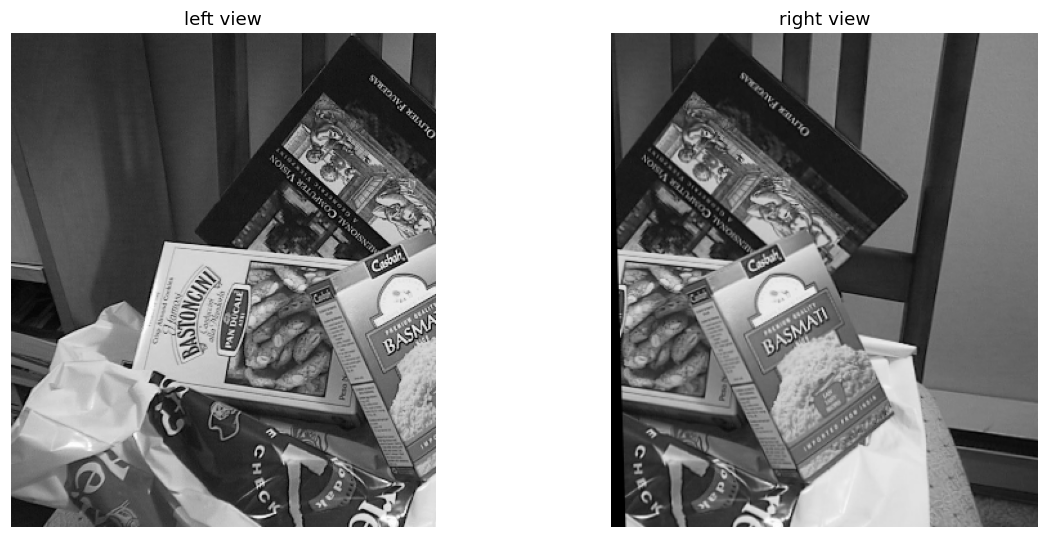

390 inliers of 407 matches


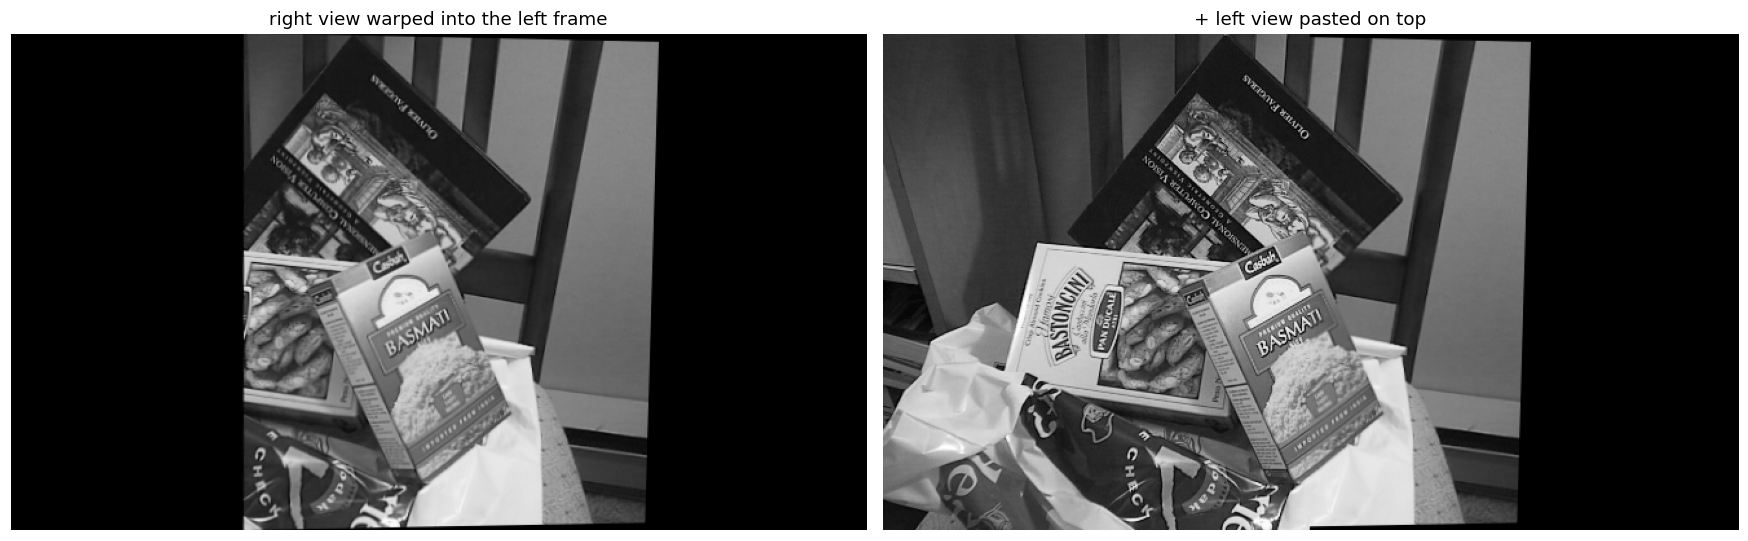

In [8]:
# PART 7 · MINI PANORAMA
# We cut the scene into two overlapping views (the right one slightly turned) and stitch them back.
# PREDICT FIRST: where will the seam show up?

left = scene[:, :330].copy()
H_cam = np.array([[1.0, 0.03, 0], [-0.02, 1.0, 0], [-1e-4, 0, 1.0]])   # simulates turning the camera
right = cv2.warpPerspective(scene[:, 180:].copy(), H_cam, (scene.shape[1] - 180, scene.shape[0]))
show(left, right, titles=("left view", "right view"), size=(12, 5))

gl, gr = cv2.cvtColor(left, cv2.COLOR_BGR2GRAY), cv2.cvtColor(right, cv2.COLOR_BGR2GRAY)
kl, dl = sift.detectAndCompute(gl, None)
kr, dr = sift.detectAndCompute(gr, None)
g = ratio_filter([p for p in flann.knnMatch(dr, dl, k=2) if len(p) == 2], 0.75)   # right -> left
src = np.float32([kr[m.queryIdx].pt for m in g]).reshape(-1, 1, 2)
dst = np.float32([kl[m.trainIdx].pt for m in g]).reshape(-1, 1, 2)
H_rl, m = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
print(f"{int(m.sum())} inliers of {len(g)} matches")

canvas_w = left.shape[1] + right.shape[1]
pano = cv2.warpPerspective(right, H_rl, (canvas_w, left.shape[0]))
seam = pano.copy(); seam[:, :left.shape[1]] = left              # overwrite: simplest blend
show(pano, seam, titles=("right view warped into the left frame", "+ left view pasted on top"), size=(16, 5))

# CHECK YOURSELF:
# - About 390 of 407 matches are inliers: a large, clean overlap.
# - The seam is at the right edge of the left view, where we pasted it on top with no blending.
#   Real stitchers BLEND across it so you can't see it.
# - warpPerspective uses inverse warping, so no holes. The black area is canvas no image covers.

In [9]:
# ★ BONUS · YOUR OWN PHOTOS
# Take 2 photos of something FLAT (a poster, a book cover) from two angles,
# or stand still and TURN your phone for two overlapping shots. Run, then choose both files.

from google.colab import files
up = files.upload()                        # choose 2 images
names = list(up)
img1 = cv2.imdecode(np.frombuffer(up[names[0]], np.uint8), cv2.IMREAD_COLOR)
img2 = cv2.imdecode(np.frombuffer(up[names[1]], np.uint8), cv2.IMREAD_COLOR)
scale = 800 / max(img1.shape[:2]); img1 = cv2.resize(img1, None, fx=scale, fy=scale)
scale = 800 / max(img2.shape[:2]); img2 = cv2.resize(img2, None, fx=scale, fy=scale)

k1, d1 = sift.detectAndCompute(cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY), None)
k2, d2 = sift.detectAndCompute(cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY), None)
g = ratio_filter([p for p in flann.knnMatch(d1, d2, k=2) if len(p) == 2], 0.75)
s = np.float32([k1[m.queryIdx].pt for m in g]).reshape(-1, 1, 2)
d = np.float32([k2[m.trainIdx].pt for m in g]).reshape(-1, 1, 2)
H12, msk = cv2.findHomography(s, d, cv2.RANSAC, 5.0)
print(f"{len(g)} matches after ratio test, {int(msk.sum())} RANSAC inliers")
h2, w2 = img2.shape[:2]
warped = cv2.warpPerspective(img1, H12, (w2, h2))
show(cv2.drawMatches(img1, k1, img2, k2, g, None, matchesMask=msk.ravel().tolist(), flags=2),
     cv2.addWeighted(img2, 0.5, warped, 0.5, 0),
     titles=("RANSAC inliers", "photo 1 warped onto photo 2 (50/50 overlay)"), size=(18, 6))

# WHAT TO LOOK FOR: if the overlay looks sharp on the flat object, H is right.
# If you walked between shots of a 3D scene, near objects look doubled: that's PARALLAX.

KeyboardInterrupt: 